# Actividad 2. Notebook baseline con MLflow

**Curso:** TC5061 - Operaciones de aprendizaje automático
**Alumno:** Jorge David Alcázar Rochín - A01252855

**Dataset:** EA SPORTS FC 27 Player Ratings (Kaggle), snapshot del 2026-09-12 con 19,789 jugadores.

**Problema:** predecir el *overall rating* de un jugador a partir de sus atributos. Como la
variable a predecir es numérica y continua, es un problema de **regresión**.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import mlflow

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

## Paso 1. Carga y descripción del dataset

In [ ]:
df = pd.read_csv("players.csv")

print("Registros:", df.shape[0])
print("Variables:", df.shape[1])
df.head()

Registros: 19789
Variables: 60


,player_id,common_name,first_name,last_name,overall_rating,position,alternate_positions,club,league,nationality,gender,preferred_foot,skill_moves,weak_foot,height_cm,weight_kg,birthdate,playstyles,pace,shooting,passing,dribbling,defending,physicality,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,edition,snapshot_date
0,227203,Alexia Putellas,Alexia,Putellas Segura,91,CM,CAM ST,London City,Barclays WSL,Spain,Women's Football,Left,5,5,NaN,NaN,1994-02-04,"Finesse Shot, Gamechanger, Tiki Taka, Inventiv...",80,90,91,92,72,75,88,90,74,94,87,91,89,83,90,94,80,80,87,92,92,89,82,80,74,90,70,78,91,93,89,92,60,82,64,15,17,11,15,10,fc27,2026-09-12
1,231747,NaN,Kylian,Mbappé,91,ST,LW,Real Madrid,LALIGA EA SPORTS,France,Men's Football,Right,5,4,NaN,NaN,1998-12-20,"Finesse Shot, Acrobatic, Low Driven Shot, Game...",96,91,80,92,29,76,74,95,78,87,87,92,80,70,74,93,97,96,93,92,82,91,90,83,77,86,61,19,91,83,86,88,15,34,24,13,5,7,11,6,fc27,2026-09-12
2,239085,NaN,Erling,Haaland,91,ST,NaN,Manchester City,Premier League,Norway,Men's Football,Left,3,3,NaN,NaN,2000-07-21,"Chip Shot, Power Shot, Precision Header, Acrob...",87,92,71,80,47,89,58,96,85,78,90,79,77,62,66,83,81,92,66,94,69,94,93,80,93,83,88,43,95,75,89,86,42,47,33,7,14,13,11,7,fc27,2026-09-12
3,192119,NaN,Thibaut,Courtois,90,GK,NaN,Real Madrid,LALIGA EA SPORTS,Belgium,Men's Football,Left,1,3,NaN,NaN,1992-05-11,"Far Throw, Far Reach, Rush Out+",87,89,78,90,46,90,14,14,13,33,12,13,19,20,35,23,42,52,63,88,45,59,68,38,70,17,23,15,13,60,27,66,20,18,16,87,89,78,90,90,fc27,2026-09-12
4,202126,NaN,Harry,Kane,90,ST,NaN,FC Bayern München,Bundesliga,England,Men's Football,Right,3,4,NaN,NaN,1993-07-28,"Precision Header, Low Driven Shot, Gamechanger...",62,94,83,82,49,83,80,96,89,86,91,80,82,69,82,87,63,62,67,94,72,92,87,76,87,91,82,42,96,86,93,92,46,44,42,8,10,11,14,11,fc27,2026-09-12


In [24]:
# Tipos de dato de cada columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19789 entries, 0 to 19788
Data columns (total 60 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   player_id                   19789 non-null  int64  
 1   common_name                 2879 non-null   str    
 2   first_name                  19789 non-null  str    
 3   last_name                   19789 non-null  str    
 4   overall_rating              19789 non-null  int64  
 5   position                    19789 non-null  str    
 6   alternate_positions         12896 non-null  str    
 7   club                        19789 non-null  str    
 8   league                      19789 non-null  str    
 9   nationality                 19789 non-null  str    
 10  gender                      19789 non-null  str    
 11  preferred_foot              19789 non-null  str    
 12  skill_moves                 19789 non-null  int64  
 13  weak_foot                   19789 non-null

### Estructura del dataset

El archivo tiene **19,789 registros** (un jugador por renglón) y **60 variables**. Las columnas se
pueden agrupar así:

- **Identificación:** `player_id`, `common_name`, `first_name`, `last_name`, `birthdate`.
- **Contexto:** `position`, `alternate_positions`, `club`, `league`, `nationality`, `gender`,
  `preferred_foot`, `edition`, `snapshot_date`.
- **Variable objetivo:** `overall_rating`, la calificación general de la carta del jugador (escala 1-99).
- **Facetas de la carta (6):** `pace`, `shooting`, `passing`, `dribbling`, `defending`, `physicality`.
  Son los seis números grandes que trae la carta.
- **Atributos detallados (34):** los que están detrás de cada faceta, agrupados por prefijo
  (`attacking_`, `skill_`, `movement_`, `power_`, `mentality_`, `defending_`).
- **Atributos de portero (5):** `goalkeeping_*`, que solo tienen sentido para los porteros.
- **Otros:** `skill_moves` y `weak_foot` (estrellas de 1 a 5), `playstyles`, `height_cm`, `weight_kg`.

## Paso 2. Análisis exploratorio (EDA)

In [25]:
# Estadisticas descriptivas de las variables numericas mas importantes
cols_interes = ["overall_rating", "pace", "shooting", "passing",
                "dribbling", "defending", "physicality",
                "skill_moves", "weak_foot"]
df[cols_interes].describe().round(2)

,overall_rating,pace,shooting,passing,dribbling,defending,physicality,skill_moves,weak_foot
count,19789.00,19789.00,19789.00,19789.00,19789.00,19789.00,19789.00,19789.00,19789.00
mean,66.72,68.18,54.90,59.17,64.10,50.89,64.96,2.39,2.92
std,6.96,10.55,13.84,9.71,9.11,16.80,9.57,0.78,0.67
min,47.00,29.00,21.00,26.00,30.00,15.00,33.00,1.00,1.00
25%,62.00,62.00,46.00,53.00,59.00,36.00,59.00,2.00,3.00
50%,67.00,69.00,57.00,60.00,65.00,55.00,66.00,2.00,3.00
75%,71.00,75.00,65.00,66.00,70.00,64.00,72.00,3.00,3.00
max,91.00,96.00,94.00,92.00,93.00,91.00,91.00,5.00,5.00


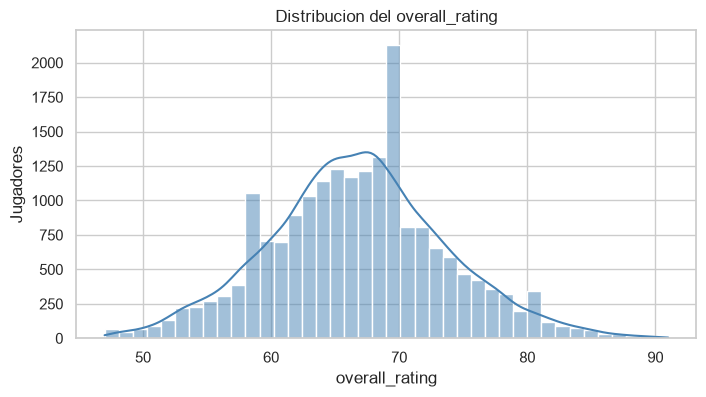

count    19789.00
mean        66.72
std          6.96
min         47.00
25%         62.00
50%         67.00
75%         71.00
max         91.00
Name: overall_rating, dtype: float64


In [26]:
# Distribucion de la variable que queremos predecir
plt.figure(figsize=(8, 4))
sns.histplot(df["overall_rating"], bins=40, kde=True, color="steelblue")
plt.title("Distribucion del overall_rating")
plt.xlabel("overall_rating")
plt.ylabel("Jugadores")
plt.show()

print(df["overall_rating"].describe().round(2))

El rating va de 47 a 91 y se concentra entre 62 y 71, con una media de 66.7. La distribución es
bastante simétrica y con forma de campana: hay muy pocos jugadores con rating alto, que es justo lo
que uno esperaría del juego.

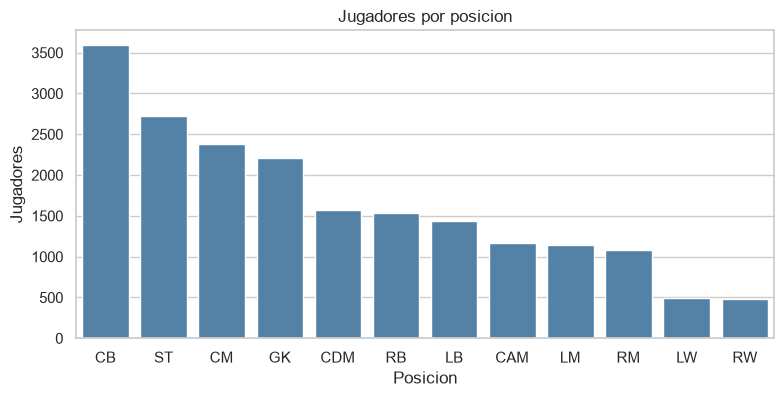

position
CB     3595
ST     2718
CM     2376
GK     2204
CDM    1568
RB     1531
LB     1435
CAM    1163
LM     1149
RM     1077
LW      489
RW      484
Name: count, dtype: int64

In [27]:
# Cuantos jugadores hay por posicion
plt.figure(figsize=(9, 4))
orden = df["position"].value_counts().index
sns.countplot(data=df, x="position", order=orden, color="steelblue")
plt.title("Jugadores por posicion")
plt.xlabel("Posicion")
plt.ylabel("Jugadores")
plt.show()

df["position"].value_counts()

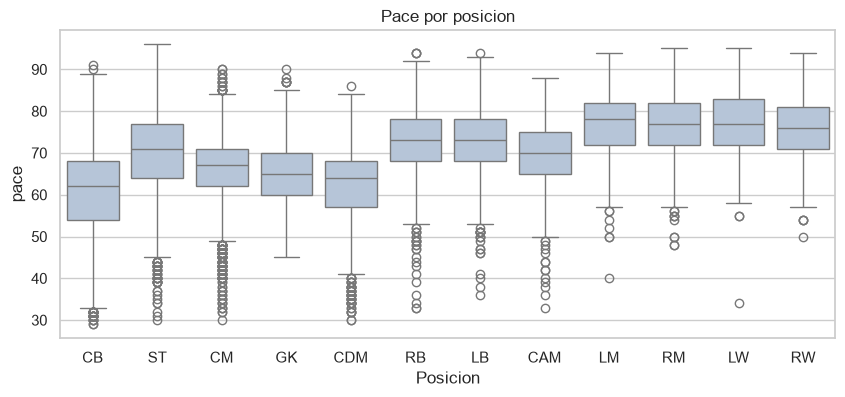

In [28]:
# Como se comportan las facetas segun la posicion (aqui se nota el caso de los porteros)
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="position", y="pace", order=orden, color="lightsteelblue")
plt.title("Pace por posicion")
plt.xlabel("Posicion")
plt.ylabel("pace")
plt.show()

En esta gráfica se ve algo importante: los porteros (GK) tienen valores de `pace` muy distintos al
resto, porque para ellos las seis facetas de la carta no significan lo mismo (su rating depende de
los atributos `goalkeeping_*`). Esto lo vamos a tomar en cuenta en la limpieza.

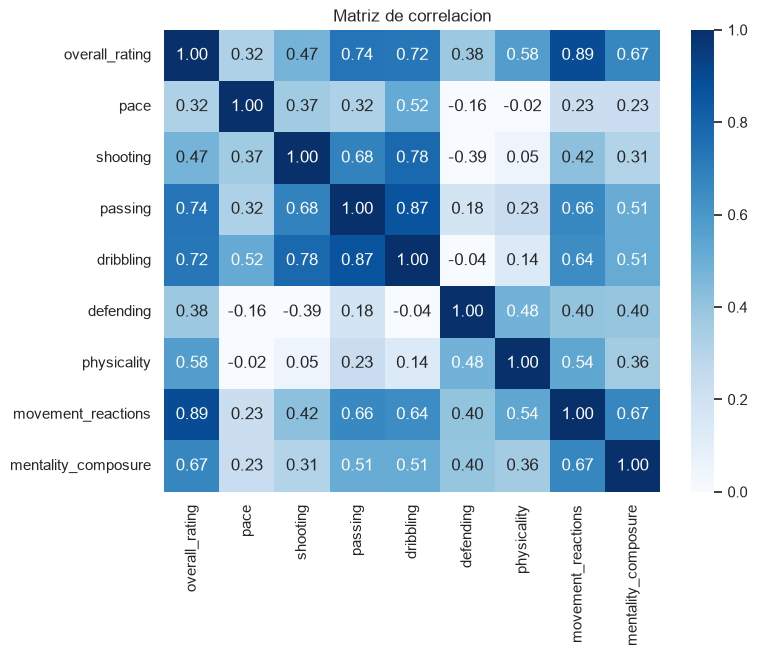

In [29]:
# Correlacion entre las facetas y el overall_rating
cols_corr = ["overall_rating", "pace", "shooting", "passing", "dribbling",
             "defending", "physicality", "movement_reactions", "mentality_composure"]
corr = df[cols_corr].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Matriz de correlacion")
plt.show()

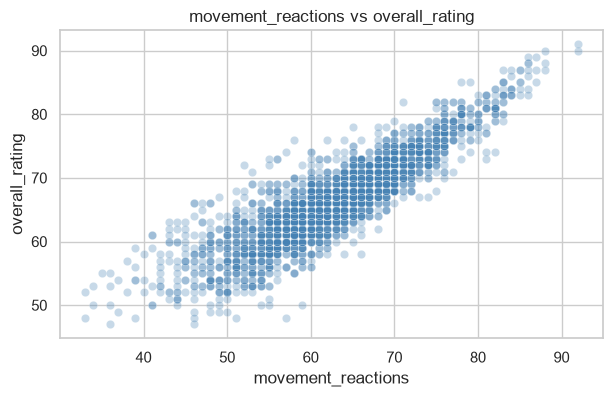

In [30]:
# La variable con mayor correlacion resulto ser movement_reactions
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df.sample(3000, random_state=42),
                x="movement_reactions", y="overall_rating",
                alpha=0.3, color="steelblue")
plt.title("movement_reactions vs overall_rating")
plt.show()

`movement_reactions` es la variable con mayor correlación con el rating (0.89), seguida de `passing`
y `dribbling`. La relación se ve claramente lineal en la gráfica de dispersión, lo que justifica
usar una regresión lineal como modelo base.

## Paso 3. Limpieza de datos

Aquí revisamos valores faltantes, duplicados, tipos de dato y valores atípicos, y documentamos qué
se decidió hacer en cada caso.

In [31]:
# 1) Valores faltantes
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)
print("Columnas con valores faltantes:")
print(faltantes)
print()
print("Porcentaje:")
print((faltantes / len(df) * 100).round(1))

Columnas con valores faltantes:
height_cm              19789
weight_kg              19789
common_name            16910
playstyles             11738
alternate_positions     6893
dtype: int64

Porcentaje:
height_cm              100.0
weight_kg              100.0
common_name             85.5
playstyles              59.3
alternate_positions     34.8
dtype: float64


**Decisión sobre los valores faltantes:**

- `height_cm` y `weight_kg` están vacías en el **100%** de los registros (EA todavía no publica esos
  datos). No se pueden imputar porque no hay ningún valor del cual partir, así que **se eliminan las
  dos columnas**.
- `common_name` (85% vacía), `playstyles` (59%) y `alternate_positions` (35%) están vacías porque el
  dato simplemente no aplica para ese jugador, no porque se haya perdido. **No se imputan** y
  tampoco se usan como variables del modelo, así que se dejan como están.
- Ninguna de las columnas numéricas que vamos a usar como variables tiene faltantes.

In [32]:
# 2) Duplicados
print("Filas duplicadas completas:", df.duplicated().sum())
print("player_id repetidos:", df["player_id"].duplicated().sum())

Filas duplicadas completas: 0
player_id repetidos: 0


**Decisión sobre duplicados:** no hay filas repetidas ni `player_id` repetidos, así que no hay nada
que eliminar.

In [33]:
# 3) Tipos de dato: birthdate viene como texto, lo pasamos a fecha y calculamos la edad
df["birthdate"] = pd.to_datetime(df["birthdate"], errors="coerce")
fecha_snapshot = pd.to_datetime(df["snapshot_date"].iloc[0])
df["edad"] = ((fecha_snapshot - df["birthdate"]).dt.days / 365.25).round(1)

print("Fecha del snapshot:", fecha_snapshot.date())
print(df[["first_name", "last_name", "birthdate", "edad"]].head())

Fecha del snapshot: 2026-09-12
  first_name        last_name  birthdate  edad
0     Alexia  Putellas Segura 1994-02-04  32.6
1     Kylian           Mbappé 1998-12-20  27.7
2     Erling          Haaland 2000-07-21  26.1
3    Thibaut         Courtois 1992-05-11  34.3
4      Harry             Kane 1993-07-28  33.1


**Decisión sobre tipos:** `birthdate` se convirtió de texto a fecha y con ella se creó la variable
`edad`, que sí es útil para el modelo (la fecha de nacimiento tal cual no lo es).

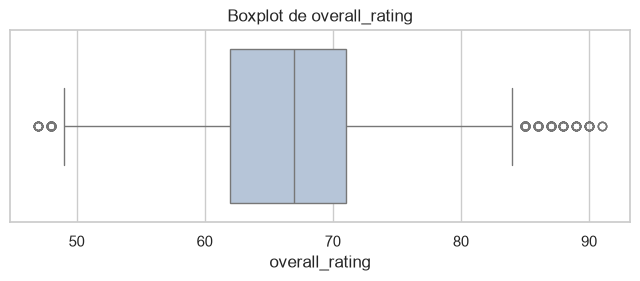

Limites segun IQR: 48.5 a 84.5
Jugadores fuera de esos limites: 229


,first_name,last_name,overall_rating,position
0,Alexia,Putellas Segura,91,CM
1,Kylian,Mbappé,91,ST
2,Erling,Haaland,91,ST
3,Thibaut,Courtois,90,GK
4,Harry,Kane,90,ST


In [34]:
# 4) Valores atipicos (outliers) en la variable objetivo
plt.figure(figsize=(8, 2.5))
sns.boxplot(x=df["overall_rating"], color="lightsteelblue")
plt.title("Boxplot de overall_rating")
plt.show()

q1, q3 = df["overall_rating"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = df[(df["overall_rating"] < lim_inf) | (df["overall_rating"] > lim_sup)]
print("Limites segun IQR: %.1f a %.1f" % (lim_inf, lim_sup))
print("Jugadores fuera de esos limites:", len(atipicos))
atipicos[["first_name", "last_name", "overall_rating", "position"]].head()

**Decisión sobre outliers:** el boxplot marca como atípicos a los jugadores de rating más alto, pero
**no se eliminan**. No son errores de captura: son las estrellas del juego (Mbappé, Putellas, etc.) y
forman parte legítima del fenómeno que queremos modelar. Quitarlos haría que el modelo no sirviera
justo para los jugadores que más interesan.

In [35]:
# 5) Separar a los porteros
# Como se vio en el EDA, las 6 facetas de la carta no describen el rating de un portero,
# asi que el modelo base se entrena solo con jugadores de campo.
print("Total de jugadores:", len(df))
print("Porteros (GK):", (df["position"] == "GK").sum())

df_limpio = df[df["position"] != "GK"].copy()
df_limpio = df_limpio.drop(columns=["height_cm", "weight_kg"])

print("Registros despues de la limpieza:", len(df_limpio))
print("Columnas despues de la limpieza:", df_limpio.shape[1])

Total de jugadores: 19789
Porteros (GK): 2204
Registros despues de la limpieza: 17585
Columnas despues de la limpieza: 59


**Resumen de la limpieza**

| Problema | Decisión |
|---|---|
| `height_cm` y `weight_kg` vacías al 100% | Se eliminan las columnas |
| `common_name`, `playstyles`, `alternate_positions` vacíos | Se dejan: el dato no aplica, no es un error |
| Duplicados | No hay, no se hace nada |
| `birthdate` como texto | Se convierte a fecha y se crea la variable `edad` |
| Outliers en `overall_rating` | Se conservan: son jugadores reales, no errores |
| Porteros | Se separan: sus facetas no son comparables con las del resto |

## Paso 4. Modelo base (baseline)

Se usa una **regresión lineal**, que es el modelo más sencillo para un problema de regresión y sirve
como punto de partida para comparar modelos más complejos después.

In [36]:
# Variables que va a usar el modelo
features = ["pace", "shooting", "passing", "dribbling", "defending", "physicality",
            "movement_reactions", "mentality_composure", "skill_moves", "weak_foot", "edad"]
target = "overall_rating"

X = df_limpio[features]
y = df_limpio[target]

print("X:", X.shape, " y:", y.shape)
print("Valores faltantes en X:", X.isna().sum().sum())

X: (17585, 11)  y: (17585,)
Valores faltantes en X: 0


In [37]:
# Division en entrenamiento (80%) y prueba (20%)
test_size = 0.2
random_state = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=random_state
)

print("Entrenamiento:", X_train.shape[0], "jugadores")
print("Prueba:", X_test.shape[0], "jugadores")

Entrenamiento: 14068 jugadores
Prueba: 3517 jugadores


In [38]:
# Entrenamiento del modelo base
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Coeficientes, para ver que variables pesan mas
coeficientes = pd.Series(modelo.coef_, index=features).sort_values(ascending=False)
print(coeficientes.round(3))

skill_moves            0.554
movement_reactions     0.389
dribbling              0.154
physicality            0.131
mentality_composure    0.106
passing                0.047
pace                   0.039
defending              0.022
edad                   0.006
shooting              -0.033
weak_foot             -0.162
dtype: float64


## Paso 5. Evaluación del modelo

Como es un problema de regresión, se usan tres métricas: **MAE** (error absoluto medio), **RMSE**
(raíz del error cuadrático medio) y **R²** (proporción de la variabilidad explicada).

In [39]:
# Predicciones sobre el conjunto de prueba
y_pred = modelo.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE : %.3f" % mae)
print("RMSE: %.3f" % rmse)
print("R2  : %.4f" % r2)

MAE : 1.908
RMSE: 2.408
R2  : 0.8755


In [40]:
# Comparacion contra un modelo tonto que siempre predice la media
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
mae_dummy = mean_absolute_error(y_test, dummy.predict(X_test))

print("MAE del modelo    : %.3f" % mae)
print("MAE prediciendo la media: %.3f" % mae_dummy)
print("Mejora: %.1f%%" % ((mae_dummy - mae) / mae_dummy * 100))

MAE del modelo    : 1.908
MAE prediciendo la media: 5.322
Mejora: 64.1%


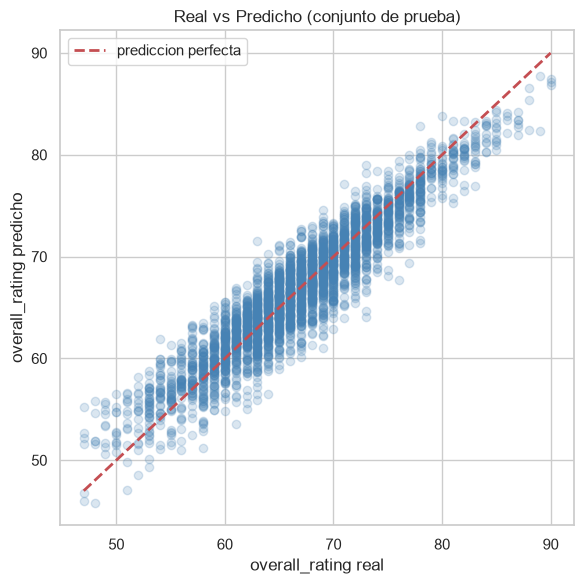

In [41]:
# Grafica de valores reales contra predichos
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.2, color="steelblue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         "r--", linewidth=2, label="prediccion perfecta")
plt.xlabel("overall_rating real")
plt.ylabel("overall_rating predicho")
plt.title("Real vs Predicho (conjunto de prueba)")
plt.legend()
plt.tight_layout()
plt.savefig("real_vs_predicho.png", dpi=100)
plt.show()

### Interpretación de los resultados

El **MAE de 1.91** significa que, en promedio, el modelo se equivoca por menos de **2 puntos de
rating**. En una escala donde los jugadores van de 47 a 91 y la mayoría se concentra entre 62 y 71,
equivocarse por 2 puntos es un error chico: el modelo distingue bien a un jugador de 65 de uno de 75.

El **RMSE de 2.41** es un poco mayor que el MAE, lo cual indica que existen algunos casos donde el
error es bastante más grande que el promedio. Mirando la gráfica de real vs predicho, esos casos
están sobre todo en los extremos: el modelo tiende a subestimar a los jugadores de rating más alto,
porque hay muy pocos de ellos para aprender ese comportamiento.

El **R² de 0.876** quiere decir que las variables elegidas explican cerca del **88%** de la
variabilidad del rating. Comparado con un modelo que siempre predice la media (MAE de 5.32), el
baseline reduce el error en aproximadamente un **64%**, así que claramente está aprendiendo algo
real y no solo repitiendo el promedio.

Como punto de partida el resultado es bueno. El techo de este modelo está en que la relación entre
atributos y rating no es perfectamente lineal, sobre todo en los extremos; un modelo de árboles o un
gradient boosting probablemente bajaría el error, y eso sería el siguiente paso.

## Paso 6. Registro del experimento en MLflow

Se registran los parámetros, las métricas y los artefactos del modelo base. Se usa SQLite como
backend porque las versiones recientes de MLflow ya no permiten el backend de archivos.

Para ver el experimento en la interfaz hay que ejecutar en la terminal, desde esta misma carpeta:

```
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

y abrir `http://localhost:5000`.

In [42]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("fc27_baseline")

with mlflow.start_run(run_name="regresion_lineal_baseline"):

    # Parametros
    mlflow.log_param("modelo", "LinearRegression")
    mlflow.log_param("n_features", len(features))
    mlflow.log_param("features", ", ".join(features))
    mlflow.log_param("test_size", test_size)
    mlflow.log_param("random_state", random_state)
    mlflow.log_param("n_train", len(X_train))
    mlflow.log_param("n_test", len(X_test))
    mlflow.log_param("filtro", "sin porteros (GK)")

    # Metricas
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("r2", r2)
    mlflow.log_metric("mae_dummy", mae_dummy)

    # grafica y el modelo entrenado
    mlflow.log_artifact("real_vs_predicho.png")
    mlflow.sklearn.log_model(modelo, name="modelo_baseline")

    run_id = mlflow.active_run().info.run_id

print("Run registrado en MLflow.")
print("run_id:", run_id)

Run registrado en MLflow.
run_id: 0f4eed58f0d34f48ae172b517bb4a39b


### Evidencia en la interfaz de MLflow

La siguiente captura muestra el run `regresion_lineal_baseline` dentro del experimento
`fc27_baseline` en la MLflow UI, con las 4 metricas y los 8 parametros registrados.

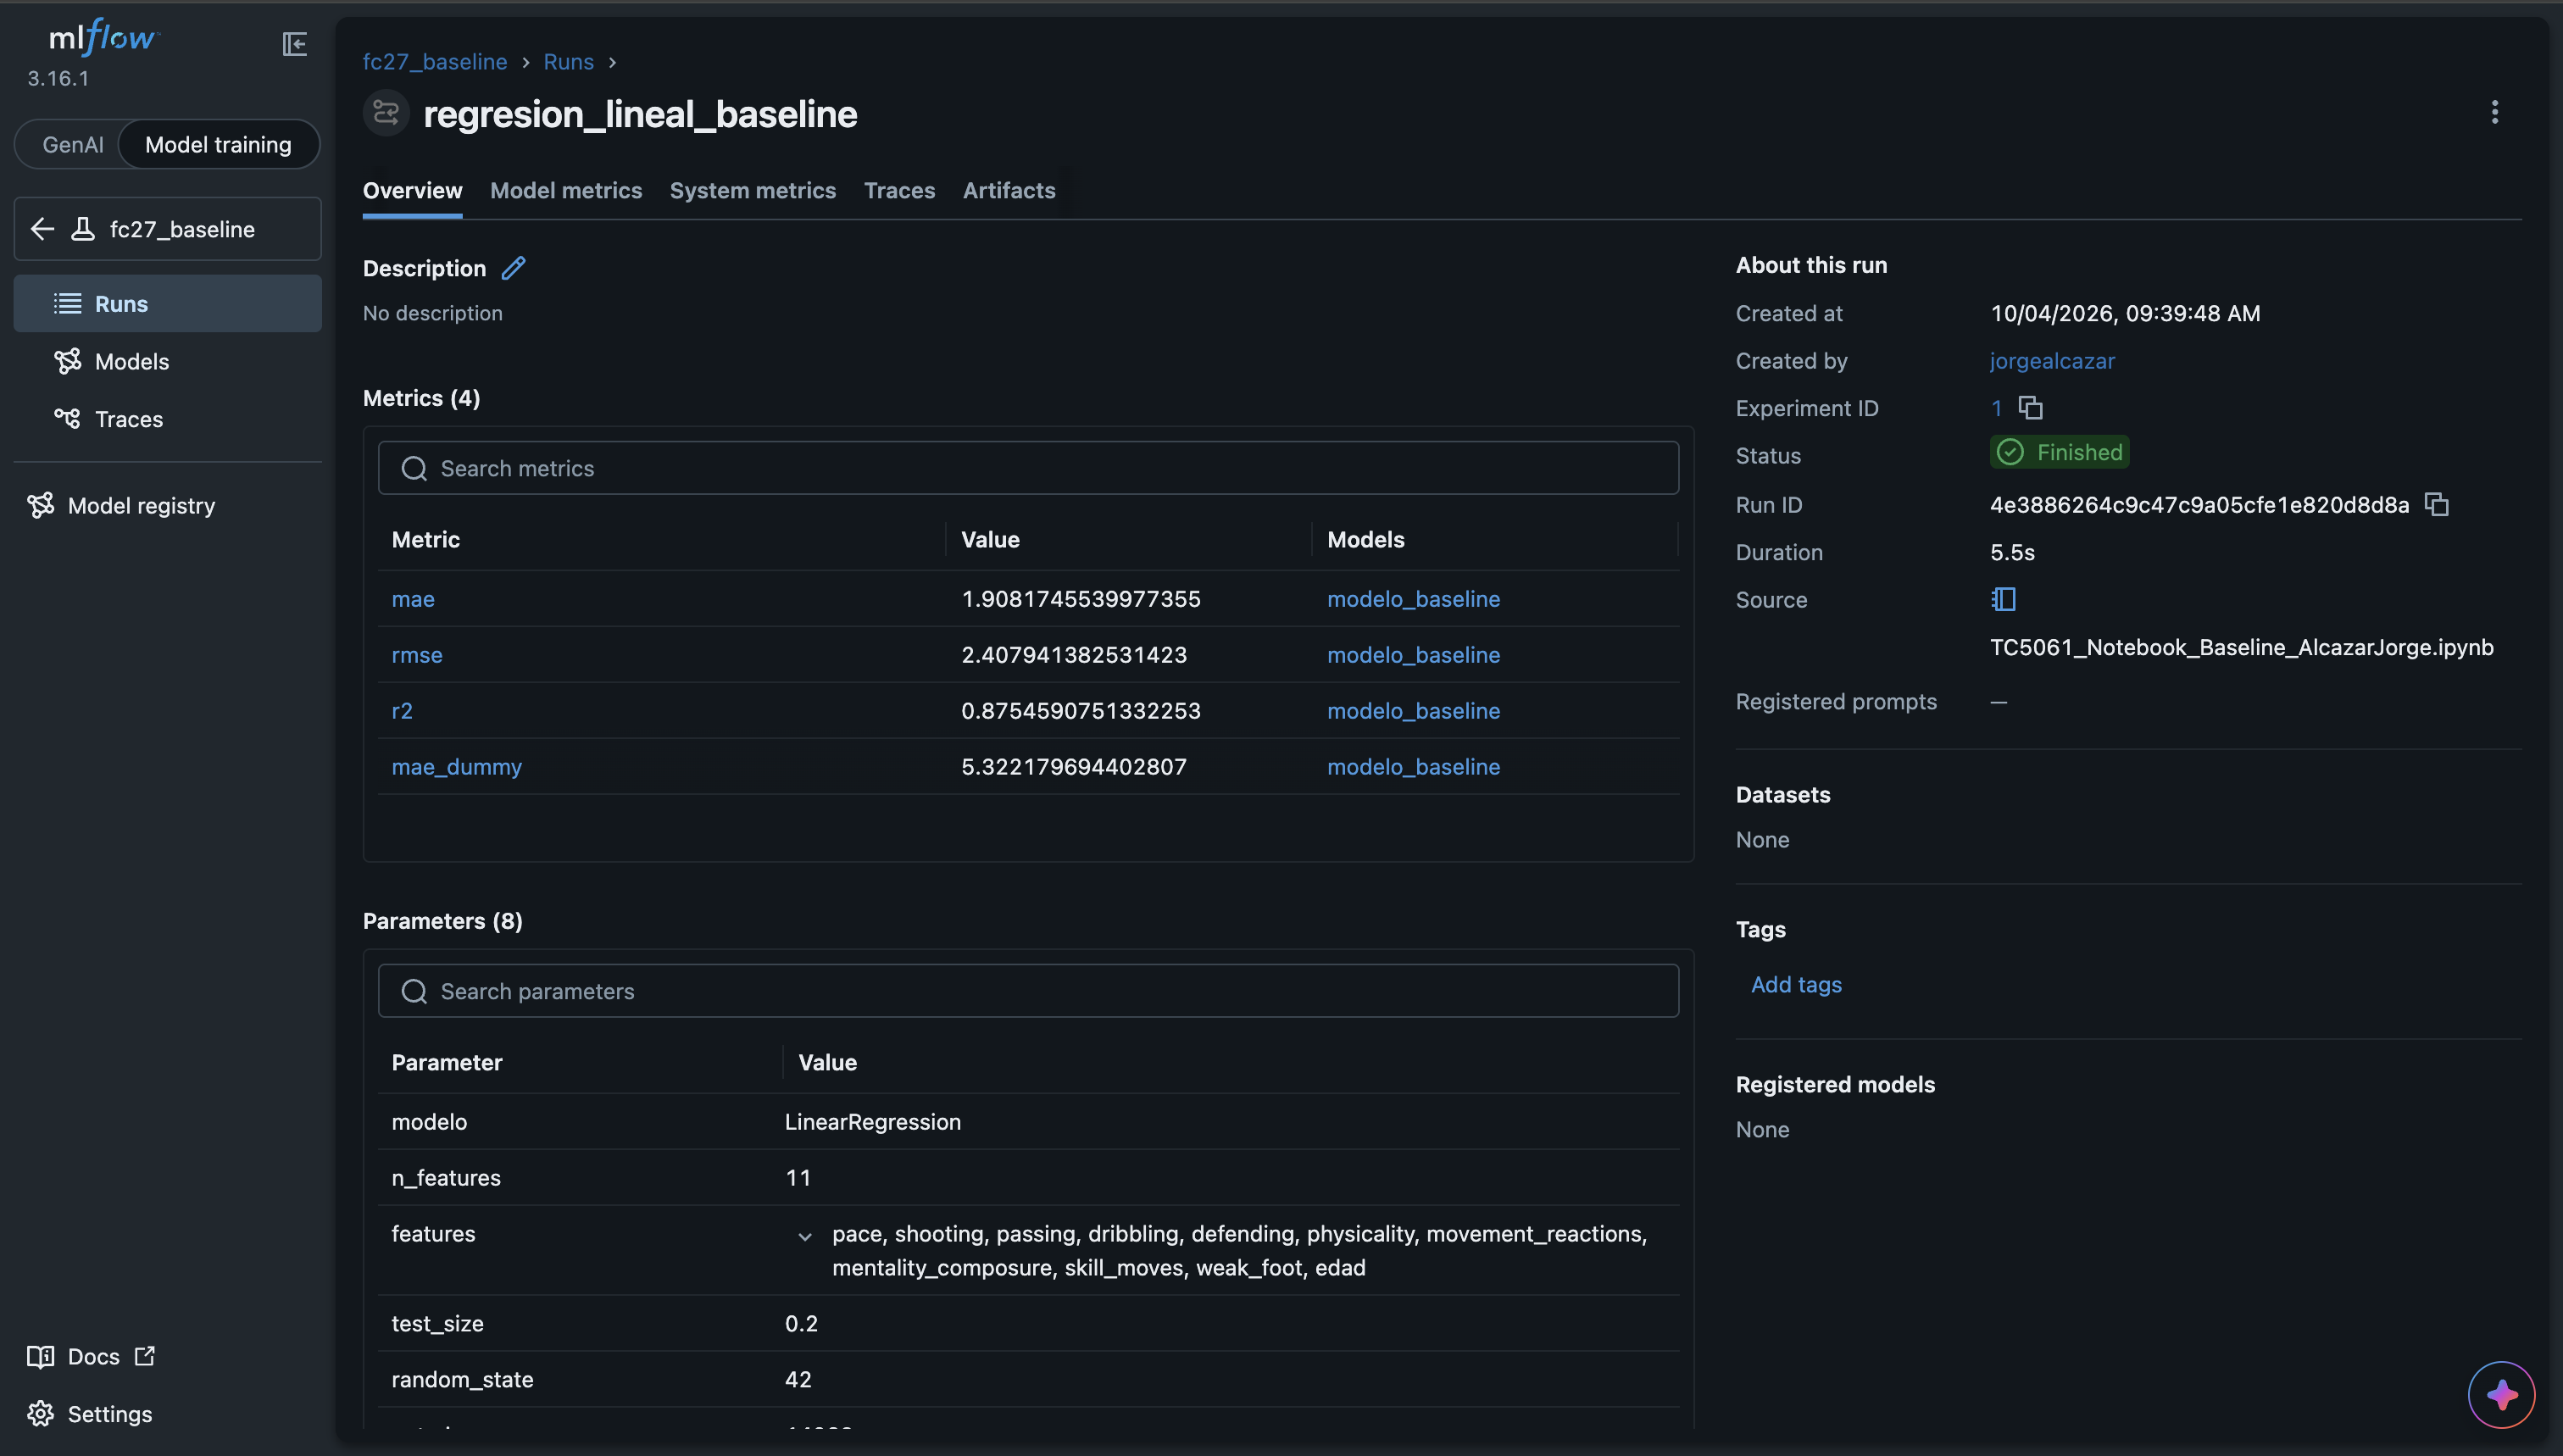

*Figura. Run registrado en MLflow (experimento fc27_baseline), mostrando metricas y parametros.*

## Paso 7. Reflexión: qué mejoraría aplicando MLOps

Todo este flujo lo hice dentro de un solo notebook y eso funciona para una entrega, pero no aguanta
el trabajo real. La primera mejora sería separar el notebook en pasos reproducibles: un script para
la limpieza, otro para entrenar y otro para evaluar, de manera que cualquier persona obtenga el
mismo resultado sin tener que ejecutar celdas en cierto orden ni acordarse de cuáles ya corrió. Junto
con eso, versionar el dataset, porque este archivo es un *snapshot* con fecha y en cuanto EA publique
una actualización mis resultados dejarían de ser reproducibles si no guardo con qué versión entrené.

La segunda mejora es aprovechar mejor MLflow. Ahorita registré una sola corrida, pero lo valioso es
registrar todas las pruebas (cambiar variables, probar otro modelo, mover el random_state) para poder
comparar métricas en la interfaz en lugar de ir anotando resultados aparte. También pondría
validaciones automáticas de los datos antes de entrenar: si mañana llega un archivo donde
`movement_reactions` viene vacía, el entrenamiento debería fallar con un mensaje claro y no entrenar
un modelo malo en silencio. Y si el modelo se usara en producción, haría falta monitorear el error
con datos nuevos para detectar cuándo se degrada.

En mi área profesional esto se conecta directo con lo que hacemos. Desarrollo aplicaciones móviles
donde se procesan documentos capturados en campo, y ahí tenemos el mismo problema: el modelo que
reconoce el texto está metido en el código, los umbrales se ajustaron a mano y nadie lleva registro
de qué versión produjo qué resultado. Cuando la precisión baja, la discusión es de opiniones y no de
datos. Llevar un registro de experimentos, versionar los datos de prueba y automatizar las métricas
nos permitiría responder con evidencia por qué una versión funciona mejor que otra, que es
exactamente el problema que tenemos hoy.